In [1]:
from pathlib import Path

import pandas as pd
import yaml


def find_repo_root(start: Path) -> Path:
    """Walk up from `start` until the folder containing pyproject.toml is found."""
    for folder in [start, *start.parents]:
        if (folder / "pyproject.toml").exists():
            return folder
    raise FileNotFoundError("pyproject.toml not found - are you inside the repo?")


ROOT = find_repo_root(Path.cwd())
config = yaml.safe_load((ROOT / "configs" / "config.yaml").read_text())

df = pd.read_csv(ROOT / config["datasets"]["ai4i"])
print(f"Repo root: {ROOT}")
print(f"Shape: {df.shape[0]} rows x {df.shape[1]} columns")

Repo root: /home/danee/projects/failsense
Shape: 10000 rows x 14 columns


## 1. Data quality: types, missing values, duplicates

In [2]:
df.head()

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
quality = pd.DataFrame(
    {
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "unique": df.nunique(),
    }
)
quality

,dtype,missing,unique
UDI,int64,0,10000
Product ID,str,0,10000
Type,str,0,3
Air temperature [K],float64,0,93
Process temperature [K],float64,0,82
Rotational speed [rpm],int64,0,941
Torque [Nm],float64,0,577
Tool wear [min],int64,0,246
Machine failure,int64,0,2
TWF,int64,0,2


In [4]:
print(f"Duplicate rows:          {df.duplicated().sum()}")
print(f"Duplicate UDI:           {df['UDI'].duplicated().sum()}")
print(f"Duplicate Product ID:    {df['Product ID'].duplicated().sum()}")

Duplicate rows:          0
Duplicate UDI:           0
Duplicate Product ID:    0


**Findings – data quality**
- 10,000 rows, 14 columns, no missing values, no duplicate rows (synthetic data).
- `UDI` and `Product ID` are unique identifiers → drop, never use as features.
  `Product ID` also starts with the `Type` letter (redundant).
- `Type` (L/M/H) is categorical → needs encoding (OneHotEncoder).
- `Machine failure` is the binary target.
- `TWF`, `HDF`, `PWF`, `OSF`, `RNF` are failure modes → **leakage risk**, must never be features.
- `Air temperature` has only 93 distinct values → rounded to 0.1 K.

## 2. Target: failure rate and failure modes

In [5]:
target = df["Machine failure"]
counts = target.value_counts().sort_index()
rate = target.mean()

print(counts.to_string())
print(f"\nFailure rate: {rate:.2%}")
print(f"Accuracy of a model that ALWAYS predicts 'no failure': {1 - rate:.2%}")

Machine failure
0    9661
1     339

Failure rate: 3.39%
Accuracy of a model that ALWAYS predicts 'no failure': 96.61%


In [6]:
FAILURE_MODES = ["TWF", "HDF", "PWF", "OSF", "RNF"]

print("Count per failure mode:")
print(df[FAILURE_MODES].sum().to_string())

any_mode = df[FAILURE_MODES].any(axis=1)
print(f"\nFailure = 1 but NO mode flagged:  {((target == 1) & ~any_mode).sum()}")
print(f"Mode flagged but failure = 0:      {((target == 0) & any_mode).sum()}")
print(f"Rows with more than one mode:      {(df[FAILURE_MODES].sum(axis=1) > 1).sum()}")

Count per failure mode:
TWF     46
HDF    115
PWF     95
OSF     98
RNF     19

Failure = 1 but NO mode flagged:  9
Mode flagged but failure = 0:      18
Rows with more than one mode:      24


In [7]:
mode_but_no_failure = (target == 0) & any_mode
print("Modes in the 18 rows with failure = 0:")
print(df.loc[mode_but_no_failure, FAILURE_MODES].sum().to_string())

Modes in the 18 rows with failure = 0:
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18


**Findings – target**
- 339 failures out of 10,000 → **failure rate 3.39 %** (strongly imbalanced).
- A model that always predicts "no failure" reaches **96.61 % accuracy** but catches **0** failures
  → accuracy is useless here; use **PR-AUC** and **Recall** (DummyClassifier as baseline).
- Failure modes overlap: 373 mode flags for 339 failures, 24 rows have more than one mode
  → failure-mode prediction is closer to **multi-label** than multi-class.
- **Inconsistencies (27 rows):**
  - 9 rows: `Machine failure = 1` but no mode flagged.
  - 18 rows: `RNF = 1` but `Machine failure = 0` (18 of 19 RNF rows).
- Decision: keep `Machine failure` as the target **as recorded**, do not edit labels by hand.
  Document in the Model Card. RNF is random by design and not predictable.

## 3. Sensor distributions: failure vs. no failure

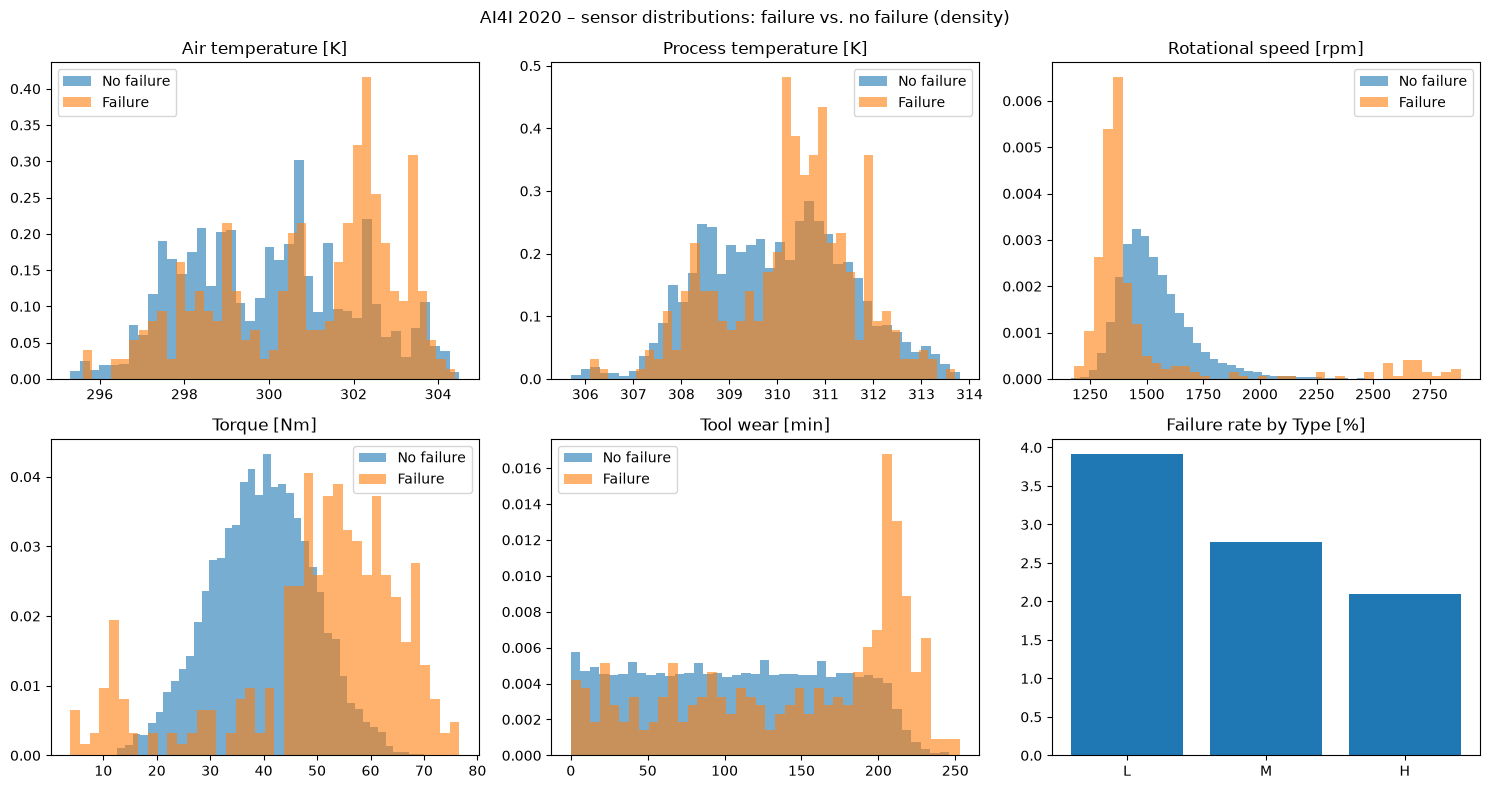

In [8]:
import matplotlib.pyplot as plt

SENSORS = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, SENSORS, strict=False):
    ax.hist(df.loc[target == 0, col], bins=40, density=True, alpha=0.6, label="No failure")
    ax.hist(df.loc[target == 1, col], bins=40, density=True, alpha=0.6, label="Failure")
    ax.set_title(col)
    ax.legend()

rate_by_type = df.groupby("Type")["Machine failure"].mean().reindex(["L", "M", "H"])
axes.flat[5].bar(rate_by_type.index, rate_by_type.values * 100)
axes.flat[5].set_title("Failure rate by Type [%]")

fig.suptitle("AI4I 2020 – sensor distributions: failure vs. no failure (density)")
fig.tight_layout()

fig_dir = ROOT / config["paths"]["reports"] / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "01_eda_distributions.png", dpi=120)
plt.show()

In [9]:
df[SENSORS + ["Machine failure"]].groupby("Machine failure").median().T.round(1)

Machine failure,0,1
Air temperature [K],300.0,301.6
Process temperature [K],310.0,310.4
Rotational speed [rpm],1507.0,1365.0
Torque [Nm],39.9,53.7
Tool wear [min],107.0,165.0


**Findings – distributions**
- **Torque** (median 39.9 → 53.7 Nm) and **rotational speed** (1507 → 1365 rpm) separate failures best.
- Failures appear at **both extremes**: high torque/low speed and very low torque/very high speed
  → non-linear pattern (power failure). A linear model will miss one side;
  tree models or the engineered feature **power = torque × speed × 2π/60** should handle it.
- **Tool wear**: failures jump at ~200–240 min (tool wear failure). Combined with high torque
  → overstrain → engineered feature **strain = tool wear × torque**.
- **Type**: failure rate L ≈ 3.9 % > M ≈ 2.8 % > H ≈ 2.1 % → useful categorical feature.
- Air temperature alone is weak; test **temperature difference = process − air** (heat dissipation).
- Next: engineer the three physical features (30.10) and compare models with/without them.